# Phase 7: Supervised Candidate Selection and Error Analysis

In [1]:
import json
import logging
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

## Notebook objective

This notebook selects the strongest supervised fraud-detection candidates from
the experiments completed in Phases 4 and 5.

The objectives are to:

- Load and validate the consolidated supervised model-comparison results.
- Rank experiments using validation PR-AUC and F1-score.
- Select top-performing and high-recall candidate models.
- Reload the saved candidate pipelines and verify their validation metrics.
- Analyze false positives and false negatives.
- Visualize validation fraud-score distributions by actual class.
- Save the candidate shortlist, candidate-selection report, and error-analysis
  report.

The untouched test set is not used for candidate selection, threshold tuning,
or evaluation in this notebook.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
BASELINE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "baseline_models"
IMBALANCE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "class_imbalance_models"

MODEL_COMPARISON_PATH = REPORTS_DIR / "model_comparison.csv"
SHORTLIST_PATH = REPORTS_DIR / "supervised_candidate_shortlist.csv"
ERROR_ANALYSIS_PATH = REPORTS_DIR / "supervised_error_analysis_report.md"
CANDIDATE_SELECTION_REPORT_PATH = (
    REPORTS_DIR / "supervised_candidate_selection_report.md"
)

DEFAULT_THRESHOLD = 0.5
SHORTLIST_SIZE = 3
MINIMUM_PRECISION_FOR_HIGH_RECALL = 0.50

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Model comparison report: %s", MODEL_COMPARISON_PATH)

2026-11-01 10:44:22,374 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 10:44:22,379 | INFO | Model comparison report: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\model_comparison.csv


## Load and validate model-comparison results

This cell loads the consolidated supervised experiment results created in
Phases 4 and 5.

It validates that:

- The model-comparison CSV exists.
- The file is not empty.
- All required evaluation columns are present.
- At least one valid PR-AUC value is available.

The displayed table shows each supervised experiment with its model type,
feature configuration, imbalance strategy, validation metrics, false positives,
and false negatives.

All metrics are validation results. The test set has not been used.

In [3]:
def load_and_validate_model_comparison(
    comparison_path: Path,
) -> pd.DataFrame:
    """Load and validate the consolidated supervised experiment results."""
    if not comparison_path.exists():
        raise FileNotFoundError(f"Model comparison report not found: {comparison_path}")

    results = pd.read_csv(comparison_path)

    required_columns = {
        "model",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
    }

    missing_columns = required_columns - set(results.columns)
    if missing_columns:
        raise ValueError(
            f"Model comparison report is missing columns: {sorted(missing_columns)}"
        )

    if results.empty:
        raise ValueError("Model comparison report contains no experiments.")

    if results["pr_auc"].isnull().all():
        raise ValueError("No valid PR-AUC values were found.")

    return results


model_comparison = load_and_validate_model_comparison(
    comparison_path=MODEL_COMPARATION_PATH
    if False
    else MODEL_COMPARISON_PATH,
)

logger.info("Loaded %s experiment results.", len(model_comparison))
model_comparison[
    [
        "model",
        "experiment_name",
        "feature_configuration",
        "imbalance_strategy",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positives",
        "false_negatives",
    ]
]

2026-11-01 10:44:22,479 | INFO | Loaded 11 experiment results.


,model,experiment_name,feature_configuration,imbalance_strategy,precision,recall,f1_score,pr_auc,roc_auc,false_positives,false_negatives
0,Logistic Regression,NaN,original_features,NaN,0.833333,0.492958,0.619469,0.687661,0.964885,7,36
1,Logistic Regression,NaN,original_plus_log_amount,NaN,0.837209,0.507042,0.631579,0.691636,0.960886,7,35
2,Logistic Regression,NaN,log_amount_and_time_hours,NaN,0.837209,0.507042,0.631579,0.693844,0.961380,7,35
3,Logistic Regression,NaN,log_amount_and_time_hours,NaN,0.837209,0.507042,0.631579,0.693844,0.961380,7,35
4,Random Forest,NaN,log_amount_and_time_hours,NaN,0.981481,0.746479,0.848000,0.821747,0.945541,1,18
5,LightGBM,NaN,log_amount_and_time_hours,NaN,0.273381,0.535211,0.361905,0.347774,0.701455,101,33
6,Logistic Regression,Logistic Regression | Class weighting,log_amount_and_time_hours,Class weighting,0.050602,0.887324,0.095745,0.706577,0.968105,1182,8
7,Random Forest,Random Forest | Class weighting,log_amount_and_time_hours,Class weighting,0.963636,0.746479,0.841270,0.849424,0.945599,2,18
8,LightGBM,LightGBM | Positive-class weighting,log_amount_and_time_hours,Positive-class weighting,0.076159,0.647887,0.136296,0.049930,0.817361,558,25
9,Logistic Regression,Logistic Regression | SMOTE,log_amount_and_time_hours,SMOTE,0.047800,0.887324,0.090713,0.709086,0.969187,1255,8


## Select supervised candidate models

This cell selects a shortlist of candidate models using validation results.

The selection policy is:

1. Remove experiments with missing or blank experiment names.
2. Rank experiments by validation PR-AUC, then F1-score.
3. Select the top three experiments by PR-AUC.
4. Add any additional high-recall candidate with:
   - Recall of at least 0.80.
   - Precision of at least 0.50.

PR-AUC is the primary ranking metric because fraudulent transactions are
extremely rare. High-recall candidates are also considered because missed fraud
can be costly, provided precision remains practical.

The selection reason is recorded for every shortlisted candidate.

In [4]:
def select_supervisor_candidates(
    results: pd.DataFrame,
    shortlist_size: int,
    minimum_precision_for_high_recall: float,
) -> tuple[pd.DataFrame, list[str]]:
    """Select candidate models using validation PR-AUC and recall constraints."""
    if "experiment_name" not in results.columns:
        raise ValueError("Model comparison report is missing 'experiment_name'.")

    valid_results = results[
        results["experiment_name"].notna()
        & results["experiment_name"].astype(str).str.strip().ne("")
    ].copy()

    valid_results["experiment_name"] = valid_results[
        "experiment_name"
    ].astype(str).str.strip()

    if valid_results.empty:
        raise ValueError("No valid experiment names were found in the comparison report.")

    ranked_results = valid_results.sort_values(
        by=["pr_auc", "f1_score"],
        ascending=[False, False],
    ).copy()

    top_pr_auc_candidates = ranked_results.head(shortlist_size)[
        "experiment_name"
    ].tolist()

    high_recall_candidates = ranked_results[
        (ranked_results["recall"] >= 0.80)
        & (ranked_results["precision"] >= minimum_precision_for_high_recall)
    ]["experiment_name"].tolist()

    selected_candidates = list(
        dict.fromkeys(top_pr_auc_candidates + high_recall_candidates)
    )

    shortlist = ranked_results[
        ranked_results["experiment_name"].isin(selected_candidates)
    ].copy()

    shortlist["selection_reason"] = shortlist["experiment_name"].map(
        lambda name: (
            "Top validation PR-AUC candidate"
            if name in top_pr_auc_candidates
            else ""
        )
        + (
            "; High-recall candidate"
            if name in high_recall_candidates
            else ""
        )
    )

    return shortlist, selected_candidates


candidate_shortlist, selected_candidate_names = select_supervisor_candidates(
    results=model_comparison,
    shortlist_size=SHORTLIST_SIZE,
    minimum_precision_for_high_recall=MINIMUM_PRECISION_FOR_HIGH_RECALL,
)

candidate_shortlist[
    [
        "experiment_name",
        "model",
        "imbalance_strategy",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positives",
        "false_negatives",
        "selection_reason",
    ]
]

,experiment_name,model,imbalance_strategy,precision,recall,f1_score,pr_auc,roc_auc,false_positives,false_negatives,selection_reason
7,Random Forest | Class weighting,Random Forest,Class weighting,0.963636,0.746479,0.841270,0.849424,0.945599,2,18,Top validation PR-AUC candidate
10,Random Forest | SMOTE,Random Forest,SMOTE,0.888889,0.788732,0.835821,0.840678,0.961678,7,15,Top validation PR-AUC candidate
9,Logistic Regression | SMOTE,Logistic Regression,SMOTE,0.047800,0.887324,0.090713,0.709086,0.969187,1255,8,Top validation PR-AUC candidate


## Save the candidate shortlist

This cell saves the selected candidate models and their validation metrics to:

```text
reports/supervised_candidate_shortlist.csv
```

The shortlist provides a reproducible record of which supervised experiments
will be considered for later hyperparameter optimization, threshold selection,
and final evaluation.

In [5]:
candidate_shortlist.to_csv(SHORTLIST_PATH, index=False)

logger.info("Supervised candidate shortlist saved to: %s", SHORTLIST_PATH)

2026-11-01 10:44:22,761 | INFO | Supervised candidate shortlist saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\supervised_candidate_shortlist.csv


## Resolve saved candidate artifacts

This cell locates the saved model and metadata artifacts for every selected
candidate.

It searches both:

- `models/supervised/class_imbalance_models/`
- `models/supervised/baseline_models/`

For each candidate, it verifies that both `model.joblib` and `metadata.json`
exist. If either artifact is missing, the notebook raises a clear error.

This step ensures that later evaluation uses the exact saved pipelines rather
than retraining the models.

In [6]:
def resolve_model_artifact_directory(
    experiment_name: str,
    baseline_models_directory: Path,
    imbalance_models_directory: Path,
) -> Path:
    """Resolve the saved artifact directory for a supervised experiment."""
    artifact_directory_name = (
        experiment_name.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )

    imbalance_directory = imbalance_models_directory / artifact_directory_name
    baseline_directory = baseline_models_directory / artifact_directory_name

    if imbalance_directory.exists():
        return imbalance_directory

    if baseline_directory.exists():
        return baseline_directory

    raise FileNotFoundError(
        f"No saved model artifact directory found for experiment: {experiment_name}"
    )


candidate_artifact_paths = {}

for experiment_name in selected_candidate_names:
    artifact_directory = resolve_model_artifact_directory(
        experiment_name=experiment_name,
        baseline_models_directory=BASELINE_MODELS_DIR,
        imbalance_models_directory=IMBALANCE_MODELS_DIR,
    )

    model_path = artifact_directory / "model.joblib"
    metadata_path = artifact_directory / "metadata.json"

    if not model_path.exists():
        raise FileNotFoundError(f"Model artifact not found: {model_path}")

    if not metadata_path.exists():
        raise FileNotFoundError(f"Model metadata not found: {metadata_path}")

    candidate_artifact_paths[experiment_name] = {
        "artifact_directory": str(artifact_directory),
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    }

    logger.info(
        "Resolved artifacts for %s: %s",
        experiment_name,
        artifact_directory,
    )

2026-11-01 10:44:22,827 | INFO | Resolved artifacts for Random Forest | Class weighting: c:\Users\use\Desktop\Credit Card Fraud Detection\models\supervised\class_imbalance_models\random_forest_class_weighting
2026-11-01 10:44:22,834 | INFO | Resolved artifacts for Random Forest | SMOTE: c:\Users\use\Desktop\Credit Card Fraud Detection\models\supervised\class_imbalance_models\random_forest_smote
2026-11-01 10:44:22,839 | INFO | Resolved artifacts for Logistic Regression | SMOTE: c:\Users\use\Desktop\Credit Card Fraud Detection\models\supervised\class_imbalance_models\logistic_regression_smote


## Load and prepare validation data

This cell loads the validation feature matrix and target vector created during
Phase 3.

It applies the selected Phase 4 feature-engineering configuration:

- `Amount_log1p`: zero-safe logarithmic transformation of `Amount`.
- `Time_hours`: elapsed transaction time converted from seconds to hours.

The transformations are applied consistently to the validation set. The `Class`
target column is not included in the feature matrix.

In [7]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

X_validation_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_validation)
)

logger.info("Validation features: %s", X_validation_engineered.shape)
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 10:44:23,114 | INFO | Validation features: (42559, 32)
2026-11-01 10:44:23,116 | INFO | Validation fraud count: 71


## Reload and evaluate candidate models

This cell reloads each saved candidate pipeline and evaluates it on the
validation set.

For each candidate, it calculates:

- Precision.
- Recall.
- F1-score.
- PR-AUC.
- ROC-AUC.
- False-positive rate.
- Confusion-matrix components.
- Number of transactions flagged.

Supervised candidates use a fraud probability threshold of `0.5` in this
notebook. This threshold is used only for consistent candidate comparison.
Final threshold optimization is performed later using validation data.

This step verifies that the saved artifacts reproduce the expected validation
behavior without retraining the models.

In [8]:
def evaluate_reloaded_candidate(
    experiment_name: str,
    model_path: Path,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
    threshold: float,
) -> tuple[dict, np.ndarray]:
    """Reload a saved pipeline, generate validation predictions, and evaluate them."""
    pipeline = joblib.load(model_path)

    validation_scores = pipeline.predict_proba(X_validation)[:, 1]
    validation_predictions = (validation_scores >= threshold).astype(int)

    confusion = confusion_matrix(y_validation, validation_predictions, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    metrics = {
        "experiment_name": experiment_name,
        "threshold": threshold,
        "precision": float(
            precision_score(y_validation, validation_predictions, zero_division=0)
        ),
        "recall": float(
            recall_score(y_validation, validation_predictions, zero_division=0)
        ),
        "f1_score": float(
            f1_score(y_validation, validation_predictions, zero_division=0)
        ),
        "pr_auc": float(average_precision_score(y_validation, validation_scores)),
        "roc_auc": float(roc_auc_score(y_validation, validation_scores)),
        "false_positive_rate": float(
            false_positive / (false_positive + true_negative)
            if (false_positive + true_negative) > 0
            else 0.0
        ),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }

    return metrics, validation_scores


candidate_validation_results = []
candidate_validation_scores = {}

for experiment_name, artifact_paths in candidate_artifact_paths.items():
    logger.info("Reloading and evaluating candidate: %s", experiment_name)

    metrics, validation_scores = evaluate_reloaded_candidate(
        experiment_name=experiment_name,
        model_path=Path(artifact_paths["model_path"]),
        X_validation=X_validation_engineered,
        y_validation=y_validation,
        threshold=DEFAULT_THRESHOLD,
    )

    candidate_validation_results.append(metrics)
    candidate_validation_scores[experiment_name] = validation_scores

candidate_validation_results_dataframe = pd.DataFrame(candidate_validation_results)

candidate_validation_results_dataframe[
    [
        "experiment_name",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
    ]
]

2026-11-01 10:44:23,147 | INFO | Reloading and evaluating candidate: Random Forest | Class weighting
2026-11-01 10:44:24,389 | INFO | Reloading and evaluating candidate: Random Forest | SMOTE
2026-11-01 10:44:26,675 | INFO | Reloading and evaluating candidate: Logistic Regression | SMOTE


,experiment_name,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives
0,Random Forest | Class weighting,0.963636,0.746479,0.841270,0.849424,0.945599,0.000047,55,2,18
1,Random Forest | SMOTE,0.888889,0.788732,0.835821,0.840678,0.961678,0.000165,63,7,15
2,Logistic Regression | SMOTE,0.047800,0.887324,0.090713,0.709086,0.969187,0.029538,1318,1255,8


## Reload validation data for consistency checks

This cell reloads the validation feature matrix and target vector and applies
the same feature-engineering transformations used earlier in this notebook.

It recreates:

- `Amount_log1p`
- `Time_hours`

The cell ensures that the reloaded candidate models are evaluated using exactly
the same validation features used during their original evaluation.

In [9]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

X_validation_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_validation)
)

logger.info("Validation features: %s", X_validation_engineered.shape)
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 10:44:27,009 | INFO | Validation features: (42559, 32)
2026-11-01 10:44:27,011 | INFO | Validation fraud count: 71


## Compare recorded and reloaded results

This cell compares the metrics recorded during original training with the
metrics produced by the reloaded candidate pipelines.

It checks:

- Precision.
- Recall.
- F1-score.
- PR-AUC.
- ROC-AUC.
- False positives.
- False negatives.
- Transactions flagged.

If all differences are within a very small tolerance, the reloaded artifacts
are consistent with the recorded validation results. Any mismatch is reported
as a warning for investigation.

In [10]:
def compare_recorded_and_reloaded_results(
    recorded_results: pd.DataFrame,
    reloaded_results: pd.DataFrame,
    tolerance: float = 1e-9,
) -> pd.DataFrame:
    """Compare recorded experiment metrics with metrics from reloaded models."""
    comparison_columns = [
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positives",
        "false_negatives",
        "transactions_flagged",
    ]

    recorded_subset = recorded_results[
        recorded_results["experiment_name"].isin(
            reloaded_results["experiment_name"]
        )
    ][["experiment_name", *comparison_columns]].set_index("experiment_name")

    reloaded_subset = reloaded_results[
        ["experiment_name", *comparison_columns]
    ].set_index("experiment_name")

    comparison = recorded_subset.join(
        reloaded_subset,
        lsuffix="_recorded",
        rsuffix="_reloaded",
    )

    mismatched_rows = []

    for column in comparison_columns:
        recorded_column = f"{column}_recorded"
        reloaded_column = f"{column}_reloaded"

        differences = (
            comparison[recorded_column] - comparison[reloaded_column]
        ).abs()

        if differences.max() > tolerance:
            mismatched_rows.append(
                {
                    "metric": column,
                    "maximum_difference": float(differences.max()),
                }
            )

    if mismatched_rows:
        logger.warning(
            "Metric mismatches detected between recorded and reloaded results: %s",
            mismatched_rows,
        )
    else:
        logger.info(
            "Reloaded candidate metrics match recorded validation results."
        )

    return comparison


metric_consistency_comparison = compare_recorded_and_reloaded_results(
    recorded_results=model_comparison,
    reloaded_results=candidate_validation_results_dataframe,
)

metric_consistency_comparison

2026-11-01 10:44:27,058 | INFO | Reloaded candidate metrics match recorded validation results.


,precision_recorded,recall_recorded,f1_score_recorded,pr_auc_recorded,roc_auc_recorded,false_positives_recorded,false_negatives_recorded,transactions_flagged_recorded,precision_reloaded,recall_reloaded,f1_score_reloaded,pr_auc_reloaded,roc_auc_reloaded,false_positives_reloaded,false_negatives_reloaded,transactions_flagged_reloaded
experiment_name,,,,,,,,,,,,,,,,
Random Forest | Class weighting,0.963636,0.746479,0.841270,0.849424,0.945599,2,18,55,0.963636,0.746479,0.841270,0.849424,0.945599,2,18,55
Logistic Regression | SMOTE,0.047800,0.887324,0.090713,0.709086,0.969187,1255,8,1318,0.047800,0.887324,0.090713,0.709086,0.969187,1255,8,1318
Random Forest | SMOTE,0.888889,0.788732,0.835821,0.840678,0.961678,7,15,63,0.888889,0.788732,0.835821,0.840678,0.961678,7,15,63


## Analyze false positives and false negatives

This cell analyzes classification errors for each candidate at the baseline
threshold of `0.5`.

It reports:

- Number of false positives.
- Number of false negatives.
- Median transaction amount for false positives.
- Median transaction amount for false negatives.
- Transaction-amount ranges for both error types.

False positives are legitimate transactions flagged for review. False negatives
are fraudulent transactions missed by the model.

Transaction amount alone does not explain or justify either error type. These
results are descriptive and help identify patterns for further investigation.

In [11]:
def analyze_classification_errors(
    experiment_name: str,
    y_true: pd.Series,
    y_score: np.ndarray,
    X_validation: pd.DataFrame,
    threshold: float,
) -> dict:
    """Analyze false positives and false negatives for one candidate."""
    predictions = (y_score >= threshold).astype(int)

    false_positive_mask = (y_true == 0) & (predictions == 1)
    false_negative_mask = (y_true == 1) & (predictions == 0)

    false_positive_amounts = X_validation.loc[
        false_positive_mask, "Amount"
    ]
    false_negative_amounts = X_validation.loc[
        false_negative_mask, "Amount"
    ]

    return {
        "experiment_name": experiment_name,
        "false_positive_count": int(false_positive_mask.sum()),
        "false_negative_count": int(false_negative_mask.sum()),
        "false_positive_median_amount": (
            float(false_positive_amounts.median())
            if len(false_positive_amounts) > 0
            else np.nan
        ),
        "false_negative_median_amount": (
            float(false_negative_amounts.median())
            if len(false_negative_amounts) > 0
            else np.nan
        ),
        "false_positive_amount_range": (
            [float(false_positive_amounts.min()), float(false_positive_amounts.max())]
            if len(false_positive_amounts) > 0
            else []
        ),
        "false_negative_amount_range": (
            [float(false_negative_amounts.min()), float(false_negative_amounts.max())]
            if len(false_negative_amounts) > 0
            else []
        ),
    }


error_analysis_results = []

for experiment_name, validation_scores in candidate_validation_scores.items():
    error_analysis_results.append(
        analyze_classification_errors(
            experiment_name=experiment_name,
            y_true=y_validation,
            y_score=validation_scores,
            X_validation=X_validation_engineered,
            threshold=DEFAULT_THRESHOLD,
        )
    )

error_analysis_dataframe = pd.DataFrame(error_analysis_results)

error_analysis_dataframe

,experiment_name,false_positive_count,false_negative_count,false_positive_median_amount,false_negative_median_amount,false_positive_amount_range,false_negative_amount_range
0,Random Forest | Class weighting,2,18,4.995,2.005,"[1.0, 8.99]","[0.0, 1809.68]"
1,Random Forest | SMOTE,7,15,8.990,1.180,"[1.0, 296.21]","[0.0, 1809.68]"
2,Logistic Regression | SMOTE,1255,8,18.730,1.090,"[0.0, 25691.16]","[0.2, 519.9]"


## Visualize candidate score distributions

This cell plots the distribution of predicted fraud scores separately for
legitimate and fraudulent transactions for each candidate model.

These plots show how well each model separates the two classes across the score
range. They also help illustrate why threshold selection matters: moving the
threshold changes the balance between flagged transactions and missed fraud.

The figure is saved to:

```text
reports/figures/supervised_candidate_score_distributions.png
```

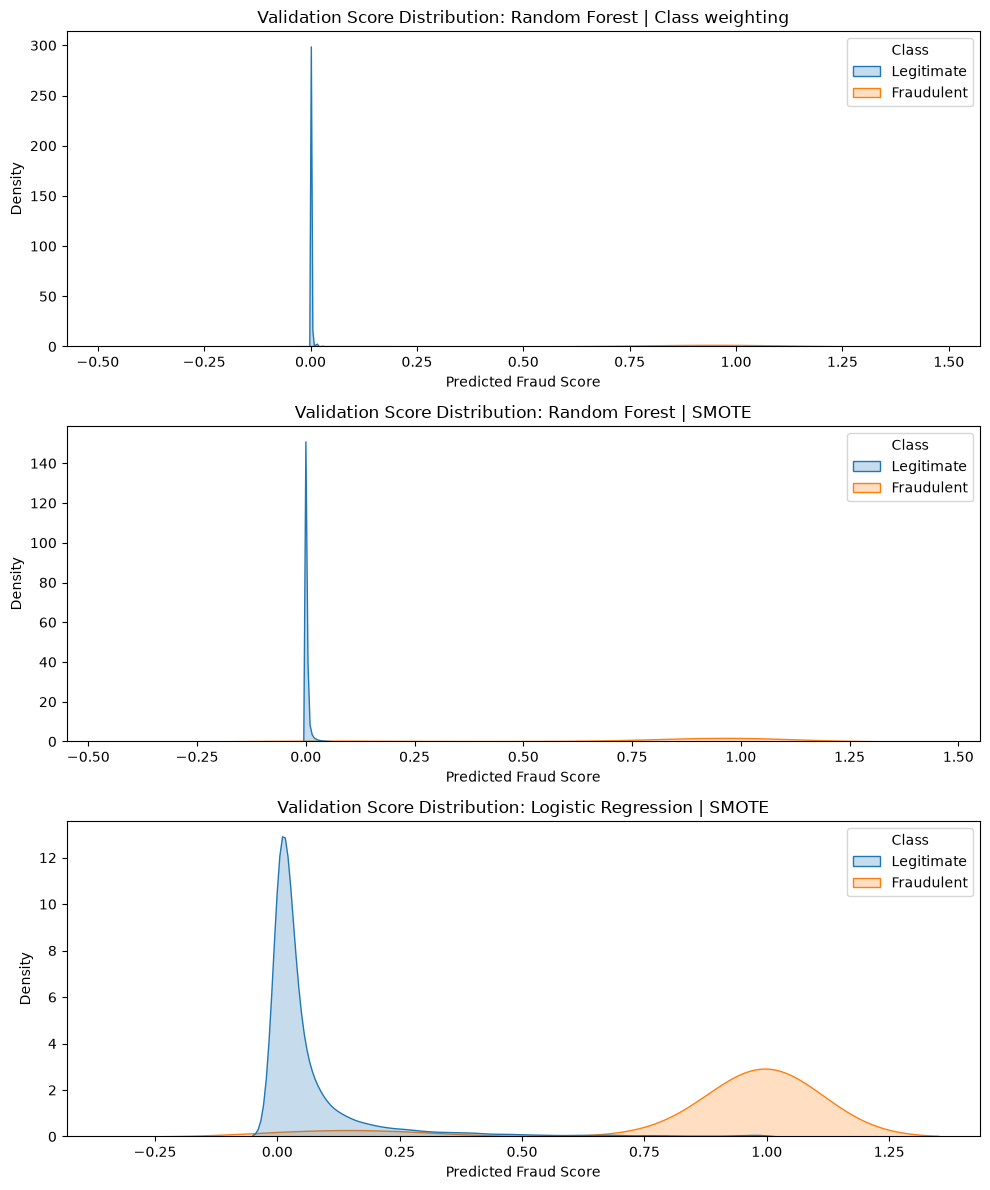

2026-11-01 10:44:32,130 | INFO | Candidate score-distribution figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\supervised_candidate_score_distributions.png


In [12]:
def plot_candidate_score_distributions(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation score distributions by actual class for each candidate."""
    experiment_names = list(scores_by_experiment)
    number_of_experiments = len(experiment_names)

    fig, axes = plt.subplots(
        number_of_experiments,
        1,
        figsize=(10, 4 * number_of_experiments),
        squeeze=False,
    )

    for axis, experiment_name in zip(axes.ravel(), experiment_names):
        scores = scores_by_experiment[experiment_name]

        plot_dataframe = pd.DataFrame(
            {
                "score": scores,
                "Class": y_true.map({0: "Legitimate", 1: "Fraudulent"}).values,
            }
        )

        sns.kdeplot(
            data=plot_dataframe,
            x="score",
            hue="Class",
            common_norm=False,
            fill=True,
            ax=axis,
        )
        axis.set_title(f"Validation Score Distribution: {experiment_name}")
        axis.set_xlabel("Predicted Fraud Score")
        axis.set_ylabel("Density")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


candidate_score_distribution_figure_path = (
    FIGURES_DIR / "supervised_candidate_score_distributions.png"
)

plot_candidate_score_distributions(
    y_true=y_validation,
    scores_by_experiment=candidate_validation_scores,
    output_path=candidate_score_distribution_figure_path,
)

logger.info(
    "Candidate score-distribution figure saved to: %s",
    candidate_score_distribution_figure_path,
)

In [13]:
def write_supervised_reports(
    shortlist: pd.DataFrame,
    reloaded_results: pd.DataFrame,
    error_analysis: pd.DataFrame,
    candidate_report_path: Path,
    error_report_path: Path,
) -> None:
    """Write candidate-selection and error-analysis reports."""
    candidate_lines = [
        "# Supervised Candidate Selection Report",
        "",
        "## Selection Policy",
        "",
        f"- Primary ranking metric: Validation PR-AUC",
        f"- Shortlist size: {SHORTLIST_SIZE}",
        "- Additional high-recall candidates require recall >= 0.80 and precision >= "
        f"{MINIMUM_PRECISION_FOR_HIGH_RECALL:.2f}",
        "- Test set: Not used",
        "",
        "## Selected Candidates",
        "",
    ]

    for _, row in shortlist.iterrows():
        candidate_lines.extend(
            [
                f"### {row['experiment_name']}",
                "",
                f"- Validation PR-AUC: {row['pr_auc']:.4f}",
                f"- Validation ROC-AUC: {row['roc_auc']:.4f}",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']:,}",
                f"- Selection reason: {row['selection_reason']}",
                "",
            ]
        )

    candidate_report_path.write_text("\n".join(candidate_lines), encoding="utf-8")

    error_lines = [
        "# Supervised Error Analysis Report",
        "",
        "## Scope",
        "",
        "- Dataset: Validation set",
        f"- Decision threshold: {DEFAULT_THRESHOLD}",
        "- Test set: Not used",
        "",
        "## Error Summary",
        "",
    ]

    for _, row in error_analysis.iterrows():
        error_lines.extend(
            [
                f"### {row['experiment_name']}",
                "",
                f"- False positives: {row['false_positive_count']:,}",
                f"- False negatives: {row['false_negative_count']:,}",
                f"- False-positive median amount: {row['false_positive_median_amount']:.2f}",
                f"- False-negative median amount: {row['false_negative_median_amount']:.2f}",
                "",
            ]
        )

    error_lines.extend(
        [
            "## Interpretation",
            "",
            "- False positives are legitimate transactions flagged for review.",
            "- False negatives are fraudulent transactions missed by the model.",
            "- Transaction amount alone does not explain or justify either error type.",
            "- Threshold optimization in a later phase may change these counts.",
        ]
    )

    error_report_path.write_text("\n".join(error_lines), encoding="utf-8")


write_supervised_reports(
    shortlist=candidate_shortlist,
    reloaded_results=candidate_validation_results_dataframe,
    error_analysis=error_analysis_dataframe,
    candidate_report_path=CANDIDATE_SELECTION_REPORT_PATH,
    error_report_path=ERROR_ANALYSIS_PATH,
)

logger.info(
    "Candidate-selection report saved to: %s",
    CANDIDATE_SELECTION_REPORT_PATH,
)
logger.info(
    "Error-analysis report saved to: %s",
    ERROR_ANALYSIS_PATH,
)

2026-11-01 10:44:32,224 | INFO | Candidate-selection report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\supervised_candidate_selection_report.md
2026-11-01 10:44:32,226 | INFO | Error-analysis report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\supervised_error_analysis_report.md


## Write candidate-selection and error-analysis reports

This cell creates two Markdown reports:

1. `reports/supervised_candidate_selection_report.md`
2. `reports/supervised_error_analysis_report.md`

The candidate-selection report documents:

- Selection policy.
- Selected candidates.
- Validation metrics.
- False positives and false negatives.
- Reason each candidate was selected.

The error-analysis report documents:

- False-positive and false-negative counts.
- Median transaction amounts for each error type.
- Interpretation and limitations.

Both reports use validation data only. The test set is not used.

In [14]:
required_supervised_artifacts = [
    SHORTLIST_PATH,
    CANDIDATE_SELECTION_REPORT_PATH,
    ERROR_ANALYSIS_PATH,
    candidate_score_distribution_figure_path,
]

for artifact_paths in candidate_artifact_paths.values():
    required_supervised_artifacts.extend(
        [
            Path(artifact_paths["model_path"]),
            Path(artifact_paths["metadata_path"]),
        ]
    )

missing_artifacts = [
    path for path in required_supervised_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing supervised candidate artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required supervised candidate artifacts were generated successfully.")
print("Phase 7 supervised candidate selection completed successfully.")

2026-11-01 10:44:32,261 | INFO | All required supervised candidate artifacts were generated successfully.


Phase 7 supervised candidate selection completed successfully.
